SAMPLE EMPLOYEE DATA
   tenure_years  monthly_overtime_hours  engagement_score  training_hours  \
0      7.490802                9.256646          2.046823       40.362180   
1     19.014286               27.095047          1.987915       47.800884   
2     14.639879               43.647292          4.625018       15.028074   
3     11.973170               36.611244          1.998185       37.492446   
4      3.120373               40.328057          2.087799       34.304759   
5      3.119890               32.939168          4.037593       49.969823   
6      1.161672               34.613828          2.798959       54.365224   
7     17.323523               42.459783          4.106842        0.729406   
8     12.022300               12.483400          1.261465       40.441195   
9     14.161452               24.471248          2.950285        3.110148   

   salary_index  absences  attrition  
0      1.157597         4          0  
1      1.344346         3          0  
2      1.30812

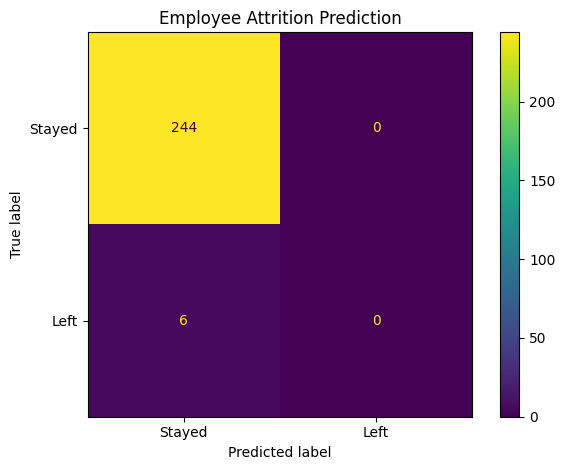


FEATURE IMPORTANCE
engagement_score          0.229
monthly_overtime_hours    0.213
training_hours            0.188
tenure_years              0.161
salary_index              0.135
absences                  0.074
dtype: float64


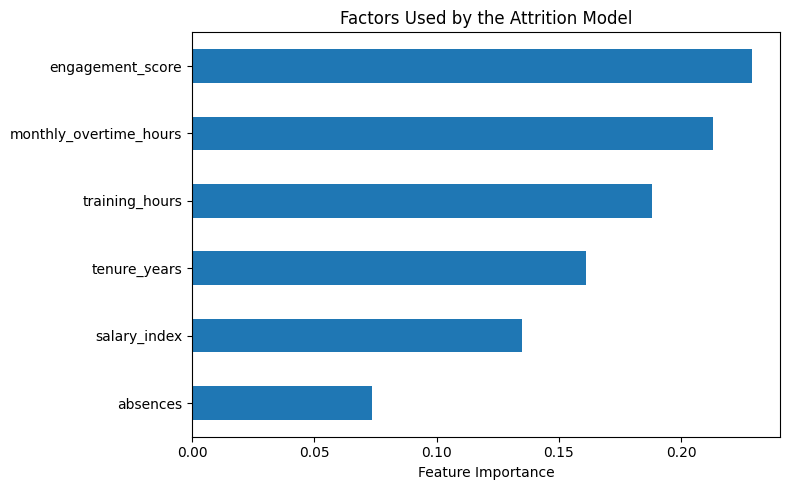


EMPLOYEE ATTRITION RISK SUMMARY
risk_category
Low Risk       983
Medium Risk      9
High Risk        8
Name: count, dtype: int64

ILLUSTRATIVE EMPLOYEE RISK REVIEW
 tenure_years  monthly_overtime_hours  engagement_score  training_hours  absences  attrition_risk risk_category                                                                                                             recommended_intervention
        10.64                   39.77              1.67           21.07         5            0.71     High Risk                                                             Review workload and overtime; Offer a confidential engagement discussion
         7.96                   38.73              1.89           19.69         2            0.69     High Risk                                                             Review workload and overtime; Offer a confidential engagement discussion
         3.74                   38.24              2.62            1.15         2            0.68   

In [1]:

# PROJECT 5: EMPLOYEE ATTRITION ROOT-CAUSE INTELLIGENCE

# STEP 1: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

np.random.seed(42)


# STEP 2: CREATE SYNTHETIC EMPLOYEE DATA

n = 1000

df = pd.DataFrame({
    "tenure_years": np.random.uniform(0, 20, n),
    "monthly_overtime_hours": np.random.uniform(0, 50, n),
    "engagement_score": np.random.uniform(1, 5, n),
    "training_hours": np.random.uniform(0, 60, n),
    "salary_index": np.random.uniform(0.7, 1.5, n),
    "absences": np.random.poisson(3, n)
})

# Generate illustrative attrition probabilities
logit = (
    -1.5
    - 0.12 * df["tenure_years"]
    + 0.045 * df["monthly_overtime_hours"]
    - 0.65 * df["engagement_score"]
    - 0.012 * df["training_hours"]
    - 0.8 * df["salary_index"]
    + 0.12 * df["absences"]
)

probability = 1 / (1 + np.exp(-logit))

# 0 = Stayed, 1 = Left
df["attrition"] = (
    np.random.rand(n) < probability
).astype(int)


# STEP 3: EXPLORE EMPLOYEE DATA

print("SAMPLE EMPLOYEE DATA")
print(df.head(10))

print("\nATTRITION DISTRIBUTION")
print(df["attrition"].value_counts())

print("\nAVERAGE EMPLOYEE METRICS BY ATTRITION")
print(df.groupby("attrition").mean().round(2))


# STEP 4: PREPARE DATA FOR MODELING

X = df.drop(columns=["attrition"])
y = df["attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


# STEP 5: TRAIN RANDOM FOREST MODEL

model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]


# STEP 6: EVALUATE MODEL

print("\nMODEL PERFORMANCE")
print("Accuracy:", round(
    accuracy_score(y_test, predictions), 3
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, probabilities), 3
))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))


# STEP 7: DISPLAY CONFUSION MATRIX

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Stayed", "Left"]
)

plt.title("Employee Attrition Prediction")
plt.tight_layout()
plt.show()


# STEP 8: ANALYZE FEATURE IMPORTANCE

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFEATURE IMPORTANCE")
print(importance.round(3))

importance.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Factors Used by the Attrition Model")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


# STEP 9: ESTIMATE ATTRITION RISK

df["attrition_risk"] = model.predict_proba(X)[:, 1]

df["risk_category"] = np.select(
    [
        df["attrition_risk"] >= 0.65,
        df["attrition_risk"] >= 0.40
    ],
    [
        "High Risk",
        "Medium Risk"
    ],
    default="Low Risk"
)

print("\nEMPLOYEE ATTRITION RISK SUMMARY")
print(df["risk_category"].value_counts())


# STEP 10: RECOMMEND ORGANIZATIONAL INTERVENTIONS

def recommend_action(row):
    actions = []

    if row["monthly_overtime_hours"] > 25:
        actions.append("Review workload and overtime")

    if row["engagement_score"] < 2.5:
        actions.append("Offer a confidential engagement discussion")

    if row["training_hours"] < 10:
        actions.append("Review training and development opportunities")

    if row["absences"] >= 6:
        actions.append("Check whether workplace support is needed")

    if not actions:
        actions.append("Continue supportive check-ins")

    return "; ".join(actions)


df["recommended_intervention"] = df.apply(
    recommend_action,
    axis=1
)

print("\nILLUSTRATIVE EMPLOYEE RISK REVIEW")
print(
    df.sort_values("attrition_risk", ascending=False)[
        [
            "tenure_years",
            "monthly_overtime_hours",
            "engagement_score",
            "training_hours",
            "absences",
            "attrition_risk",
            "risk_category",
            "recommended_intervention"
        ]
    ].head(15).round(2).to_string(index=False)
)


# STEP 11: BUSINESS RECOMMENDATIONS

print("\nBUSINESS RECOMMENDATIONS")
print("1. Review workload distribution and excessive overtime.")
print("2. Improve employee engagement and communication.")
print("3. Provide relevant training and career development.")
print("4. Review compensation fairness at an organizational level.")
print("5. Evaluate retention programs using appropriate outcome measures.")

print("\nPROJECT 5 COMPLETED SUCCESSFULLY")
print("Note: Synthetic data is used for demonstration.")
